In [2]:
import pandas as pd

# Load your iris dataset
df = pd.read_csv('1) iris.csv')  # or whatever your file is named

# Look at first few rows
print("First 5 rows:")
print(df.head())

# Check the shape
print(f"\nShape: {df.shape}")

# Check column names
print(f"\nColumn names:")
print(df.columns.tolist())

First 5 rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Shape: (150, 5)

Column names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


In [3]:
# Get basic info about the dataset
print("Dataset Info:")
print(df.info())

# Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Check basic statistics
print("\nBasic Statistics:")
print(df.describe())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Basic Statistics:
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.8

In [6]:
# Features (X) - everything except Species
X = df.drop('species', axis=1)

# Target (y) - just Species
y = df['species']

print("Features (X) - what we use to predict:")
print(X.head())
print(f"\nShape of X: {X.shape}")


print("Target (y) - what we're predicting:")
print(y.head())
print(f"\nShape of y: {y.shape}")

print("\nWhat species are we predicting?")
print(y.unique())

Features (X) - what we use to predict:
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2

Shape of X: (150, 4)
Target (y) - what we're predicting:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object

Shape of y: (150,)

What species are we predicting?
['setosa' 'versicolor' 'virginica']


In [7]:
from sklearn.model_selection import train_test_split

# Split the data
# 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set size:", X_train.shape[0], "flowers")
print("Testing set size:", X_test.shape[0], "flowers")

print("\nTraining set - species distribution:")
print(y_train.value_counts())

print("\nTesting set - species distribution:")
print(y_test.value_counts())

Training set size: 120 flowers
Testing set size: 30 flowers

Training set - species distribution:
species
versicolor    41
setosa        40
virginica     39
Name: count, dtype: int64

Testing set - species distribution:
species
virginica     11
setosa        10
versicolor     9
Name: count, dtype: int64


In [8]:
from sklearn.preprocessing import StandardScaler

# Look at the numbers before scaling
print("Before scaling - first flower:")
print(X_train.iloc[0])

# Create scaler
scaler = StandardScaler()

# Fit and transform the training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform the test data (using same scaler)
X_test_scaled = scaler.transform(X_test)

# Look at the numbers after scaling
print("\nAfter scaling - first flower:")
print(X_train_scaled[0])

print("\nMean after scaling", X_train_scaled.mean().round(10))
print("Std after scaling", X_train_scaled.std().round(2))

Before scaling - first flower:
sepal_length    4.6
sepal_width     3.6
petal_length    1.0
petal_width     0.2
Name: 22, dtype: float64

After scaling - first flower:
[-1.47393679  1.22037928 -1.5639872  -1.30948358]

Mean after scaling 0.0
Std after scaling 1.0


In [10]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN model with 3 neighbors
knn = KNeighborsClassifier(n_neighbors=3)

# Train the model
knn.fit(X_train_scaled, y_train)

print("Parameters used:")
print(knn.get_params())

Parameters used:
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}


In [15]:
# Predict species for the test flowers
y_pred = knn.predict(X_test_scaled)

# Compare first 10 predictions vs actual
print("First 10 predictions:")
print("Predicted:", y_pred[:10])
print("Actual:   ", y_test.values[:10])

First 10 predictions:
Predicted: ['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor' 'setosa'
 'versicolor' 'virginica' 'versicolor' 'versicolor']
Actual:    ['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor' 'setosa'
 'versicolor' 'virginica' 'versicolor' 'versicolor']


The 10 predictions are correct

In [17]:
from sklearn.metrics import accuracy_score

# Calculate how many we got right
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"That means {accuracy*100:.2f}% of flowers were classified correctly")

Accuracy: 1.0000
That means 100.00% of flowers were classified correctly


KNN with K=3 is working perfectly on Iris

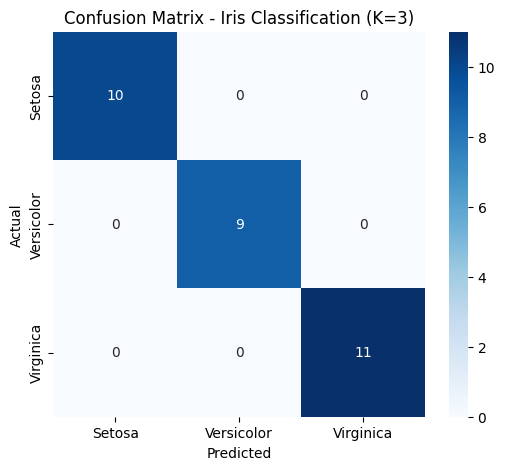

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Get predictions
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot as graph
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Setosa', 'Versicolor', 'Virginica'],
            yticklabels=['Setosa', 'Versicolor', 'Virginica'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Iris Classification (K=3)')
plt.show()

In [19]:
from sklearn.metrics import precision_score, recall_score

# Precision
precision = precision_score(y_test, y_pred, average=None)
print(f"Precision: {precision}")

# Recall
recall = recall_score(y_test, y_pred, average=None)
print(f"Recall: {recall}")

Precision: [1. 1. 1.]
Recall: [1. 1. 1.]
